# Release & recapture — single-atom temperature

For `*-ReleaseRecapture.h5` from `experiments/release_recapture.py`. Per trial: load → image → **FORT off for t** → back on → image. A hotter atom flies further while the trap is off and is less likely to be recaptured, so the recapture curve $P(t)$ encodes the temperature.

Two results, kept separate on purpose:

| | needs | use it for |
|---|---|---|
| **half-recapture time** $t_{1/2}$ (where $P(t)/P(0)=0.5$) | nothing | comparing runs: longer = colder |
| **temperature** $T$ in µK | $U_0$ and $w_0$ **at the release depth** | an absolute number |

The temperature comes from a binomial maximum-likelihood fit of $A\cdot P_{MC}(t;T)$, where $P_{MC}$ is a Monte Carlo of a thermal atom in the full 3D Gaussian trap (Tuchendler *et al.*, PRA **78**, 033425 (2008)) and $A$ absorbs every release-independent loss (pinned by the $t=0$ point the experiment always takes).

**Release depth matters.** The run records whether it released from the loading trap (`nominal_trapdepth`) or the low trap (`amp3`, after the same adiabatic ramp as Rate_measurement). Give $U_0$ for *that* depth. $T$ depends only weakly on it: on RIDs 3748/3751/3754, going from $U_0$ = 312 µK to 1018 µK moved $T$ by ×1.43 ($T\propto U_0^{0.3}$), so a 20 % error in $U_0$ is ~6 % in $T$. The fit quality does not discriminate between $U_0$ values, so $U_0$ must come from an independent measurement. $t_{1/2}$ does not depend on it at all.

In [66]:
# ---------------------------------------------------------------------------
# KERNEL CHECK -- run this FIRST.
# matplotlib cannot draw in the `artiq7_claude` env (numpy 1.23.5, broken BLAS:
# its affine transforms call np.dot while rendering, so plotting SEGFAULTS and
# the client reports "The Kernel crashed"). This analysis needs only
# numpy / h5py / matplotlib, NOT artiq -- so run it on plain Python 3.11:
#     VS Code -> kernel picker (top right) -> Python 3.11
# The probe runs np.dot in a SUBPROCESS, so a broken BLAS kills the child.
# ---------------------------------------------------------------------------
import subprocess, sys

_blas = subprocess.run(
    [sys.executable, "-c",
     "import numpy as np; np.dot(np.ones((8, 8)), np.ones((8, 8)))"],
    capture_output=True)
if _blas.returncode != 0:
    print("!" * 74)
    print("!! BROKEN BLAS in this kernel -- plotting WILL crash it.")
    print("!!   kernel : {}".format(sys.executable))
    print("!!   fix    : switch the kernel to Python 3.11, then re-run.")
    print("!" * 74)
else:
    print("BLAS ok -- plotting is safe in this kernel.")
    print("kernel:", sys.executable)

try:
    import ipympl  # noqa: F401
    get_ipython().run_line_magic("matplotlib", "widget")
except ImportError:
    get_ipython().run_line_magic("matplotlib", "inline")

import os, importlib
import matplotlib

sys.path.insert(0, os.getcwd())
import analyze_release_recapture as RR
importlib.reload(RR)
from analyze_release_recapture import (find_run, find_runs, load_run, recapture_curve,
                                       half_recapture_time, trap_params, analyze,
                                       signal_histograms)

print("matplotlib backend:", matplotlib.get_backend())
print("release-recapture runs:", [RR._rid_of(p) for p in find_runs()])

BLAS ok -- plotting is safe in this kernel.
kernel: c:\Users\CS-Node\AppData\Local\Programs\Python\Python311\python.exe
matplotlib backend: inline
release-recapture runs: [3748, 3751, 3754, 3757]


## Trap parameters at the release depth

Fill these in for the depth the run released from. Either give the depth directly (`U0_UK`), or the **radial trap frequency measured at that depth** (`F_RADIAL_KHZ`, e.g. from `trap_frequency.py` / `Parametric_heating.py`) and it is converted with $U_0 = m\,\omega_r^2 w_0^2/4$ — the same formula as `fitting/trap_oscillation.py`. The waist is always required.

Leave them `None` to get only the model-free curve and $t_{1/2}$.

In [67]:
RID          = None    # None = latest run; or e.g. 3700
W0_UM        = 1.6   # FORT waist (um)                       -- required for T
U0_UK        = 312    # trap depth at the release depth (uK)  -- or:
F_RADIAL_KHZ = None   # radial trap frequency at that depth (kHz)
THRESHOLD    = 13    # None = the run's own flags; a number re-thresholds from raw counts

--- ReleaseRecapture  RID 3757 ---
file          : C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\results\2026-11-01\19\000003757-ReleaseRecapture.h5
released from : LOW trap (amp3, after the adiabatic ramp)
release amp   : 0.0946  (min 0.0929 / max 0.0964 over loaded trials)
trials        : 3100, loaded 2490 (80%)   [re-thresholded at 13]

  t_release    recaptured / loaded    P (1 sigma Wilson)
     0.00 us      86 / 86               1.000  [0.989, 1.000]
    10.00 us      73 / 73               1.000  [0.986, 1.000]
    20.00 us      82 / 85               0.965  [0.939, 0.980]
    30.00 us      67 / 75               0.893  [0.852, 0.924]
    40.00 us      65 / 73               0.890  [0.848, 0.922]
    50.00 us      56 / 80               0.700  [0.647, 0.749]
    60.00 us      57 / 83               0.687  [0.634, 0.735]
    70.00 us      47 / 76               0.618  [0.562, 0.672]
    80.00 us      37 / 74               0.500  [0.442, 0.558]
    90.00 us      39 / 79          

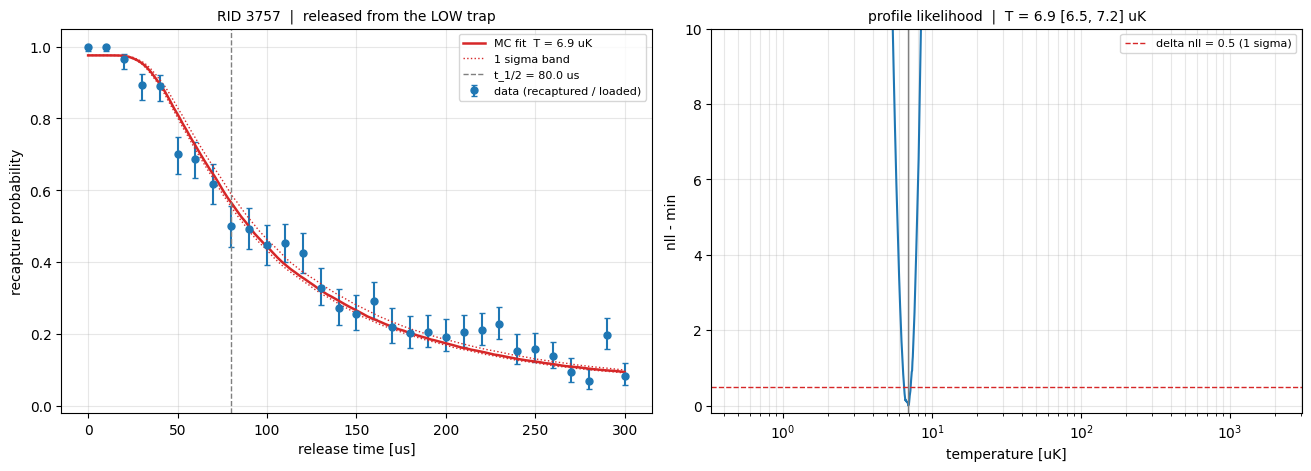

In [68]:
res = analyze(find_run(RID), w0_um=W0_UM, U0_uK=U0_UK, f_radial_kHz=F_RADIAL_KHZ,
              threshold=THRESHOLD)

## Atom signal histograms

Net counts (SPCM1 + SPCM2 minus that trial's background) for both images, with the threshold that decided *loaded* and *recaptured*.

- **A — image 1, all trials:** the no-atom and one-atom peaks. The threshold belongs in the valley between them.
- **B — image 2, loaded trials only**, split into $t=0$ (no release) and $t>0$. A recaptured atom sits in the same bright peak as image 1; a lost one drops to the no-atom peak. Unloaded trials are excluded because image 2 is skipped for them (stored as 0).

If the threshold sits inside a peak, re-run the analysis above with `THRESHOLD` set to the valley.

--- atom signal  RID 3757  (threshold 13, override) ---
background (both SPCMs)  : mean 3.7 counts
image 1, all trials      : 3100 trials, 80% above threshold
    no-atom peak  (<= thr): mean 1.0   |   atom peak (> thr): mean 36.3
image 2, t = 0 (no release): 86 trials, 100% above threshold
image 2, t > 0             : 2406 trials, 38% above threshold
Saved figure: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\results\2026-11-01\19\release_recapture_signal_RID3757.png


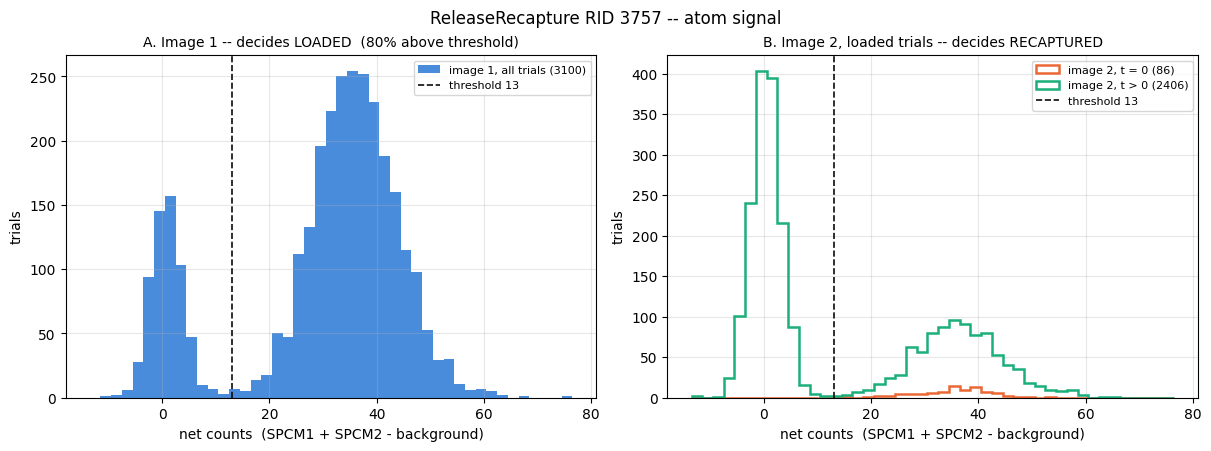

In [69]:
hist = signal_histograms(find_run(RID), threshold=THRESHOLD)

## All runs at a glance (model-free)

Useful for a high-trap vs low-trap pair. If the ramp is adiabatic, a harmonic trap keeps $E/\omega$ constant, so the temperature should scale as $T_\text{low}\approx T_\text{high}\sqrt{U_\text{low}/U_\text{high}}$ — fit both runs with their own $U_0$ and compare.

In [70]:
print("%6s  %-6s  %8s  %8s  %7s" % ("RID", "depth", "loaded", "P(0)", "t_1/2"))
for p in find_runs():
    data, meta, rid = load_run(p)
    rows = recapture_curve(data, meta)
    th = half_recapture_time(rows)
    p0 = next((r["p"] for r in rows if r["t_us"] == 0.0 and r["n"]), float("nan"))
    print("%6d  %-6s  %8d  %8.3f  %7s"
          % (rid, "LOW" if meta["release_at_low_trap"] else "HIGH",
             int((data["rr_loaded"] > 0.5).sum()), p0,
             "%.1f us" % th if th is not None else "-"))

   RID  depth     loaded      P(0)    t_1/2
  3748  HIGH         419     1.000  65.0 us
  3751  HIGH         975     1.000  42.7 us
  3754  HIGH        2465     0.987  61.1 us
  3757  LOW         2490     0.988  89.6 us


## Reading the result

1. **$P(0)$ is not 1, and that is fine.** It is survival through two images with no release at all; the fit's amplitude $A$ takes it out, so only the *shape* of the decay sets $T$.
2. **Check $\chi^2/\text{dof}$.** A poor fit usually means the trap parameters are wrong (the shape, not just the scale, depends on $w_0$ and $z_R$) or the range misses the decay — extend `t_release_max_us` if $t_{1/2}$ is "not reached".
3. **$kT/U_0 > 0.1$** triggers a warning: the initial positions come from the harmonic approximation of the trap, which overweights the outer region for a hot atom.
4. **The release is timed on the FORT RF switch.** The AOM delay shifts off and on equally; only the ~0.1–0.2 µs rise/fall is unaccounted, negligible for releases ≥ 5 µs.
5. **Validated on synthetic data** (U$_0$ = 1 mK, w$_0$ = 1.5 µm, T = 20 µK, 80 loaded trials per release time, 21 times): 20 seeds give mean $T$ = 20.4 µK, scatter 0.8 µK, 1σ coverage 16/20. An independent re-implementation of the Monte Carlo agrees to 0.01 in $P$.